## Execution record (real data) — read first

This copy of the revision notebook was **executed on the actual collected data**, not on synthetic data.

**Settings changed from the template (cell 3), nothing else in the code was changed:**
- `USE_SYNTHETIC = False`, `FAST_DEMO = False` (full protocol), `DATA_DIR = Path('real_data')`.
- `OUTER_FOLDS = 3` instead of 5. With 16 recording runs per segment (8 normal, 8 faulty for that segment's label), 4 or 5 grouped outer folds produce validation folds without one of the classes, which the notebook correctly refuses. Repeats = 3, inner folds = 3.

**Input data (`real_data/`):** the four original training files `forward_AC.csv`, `forward_CB.csv`, `backward_CA.csv`, `backward_BC.csv` (columns `Pressure`, `Time`, `Mechanism`), with one added column `Block`.
- `Block` is the recording run each row comes from (one raw Node-RED export per condition, e.g. `A_B_3.5_N_Y`: forward direction, 3.5 bar, no fault A–C, fault C–B). It was **verified, not inferred**: every row of the training files was matched value by value and in order to the raw per-condition recording files in `DATASET for ML/` (script `verify_blocks.py`). 16 runs per segment.
- `forward_CB.csv`: 2 of its 424 rows (6 bar, faulty, 2277 ms and 2279 ms; file lines 371–372) do **not** occur in the raw recordings; they repeat lines 368–369. They were excluded here so that every analysed record traces to a raw measurement (422 rows). The other three files trace completely (424, 421, 421 rows). `backward_BC` has one raw record (3.5 bar, faulty, 4670 ms) not present in the training file; the matching pass is missing from the raw `backward_CA` recording, which is why both backward files have 421 rows.
- No session/day identifiers exist, so the grouping unit is the recording run, not an acquisition day.

**Validation protocol actually used:** grouped repeated nested cross-validation with the recording run as the group (`validation_protocol = grouped`, `verified_group_column = block_id` in `run_manifest.json`). Random-row results appear only in the RF diagnostic of Section 8. No untouched holdout exists (`HOLDOUT_SESSION_IDS = []`), so Sections 10–11 report nothing. No augmentation (no documented timing-noise estimate) and no live telemetry (none exists).

Executed on Python 3.13.18, scikit-learn 1.9.1 (newer than the versions the template was tested with). Outputs were captured by a small runner script because Jupyter was not available in the execution environment; the code cells are unchanged apart from the settings above.


# Machine-learning revision laboratory: pneumatic-actuator monitoring
**For Alisher Yelseitov and Zhalgas Bolatbayev, with Tohid Alizadeh and Berdakh Abibullaev**

This Google Colab notebook turns the ML reviewer requests into executable experiments.
It is a **template tested with synthetic data, not a completed revision experiment**.
No synthetic number, plot, confidence interval, or timing is evidence for the manuscript.

**Start in Colab:** File → Upload notebook → upload this `.ipynb`; use a CPU runtime;
Runtime → Run all. The default demonstration generates data, runs the analyses, and exports
CSV tables, figures, split records, and a run manifest. A GPU is unnecessary.
For real work, upload the actual CSVs using the Files sidebar or mount your own Google Drive,
set `USE_SYNTHETIC=False`, edit the column map and paths, and document actual sessions.
Run the audit first. Do not invent acquisition IDs or repair counts to match the paper.

## How to use each section
Each section states **Reviewer request → What we do → Evidence produced → What remains**.
Reviewer numbering follows the supplied response draft; sub-bullets under Reviewer 2 are
identified by topic. Reviewer wording below is paraphrased.

**Revision constraint: existing data only.** No additional physical experiments, acquisition sessions, intermediate-pressure runs or live-system tests will be performed for this revision. New computational analyses of the already collected data are permitted. The notebook uses actual session/block metadata if available; otherwise it runs a clearly qualified random-row analysis. It does not manufacture independent sessions or require a new test set.

## 1. Reviewer requests under the existing-data constraint
| Request | Feasible work now | Limitation to acknowledge |
|---|---|---|
| R1 distributions; R2 #2; R3 #4 | Audit actual counts by pressure/class and available sessions | No expansion of the physical dataset |
| R1 leakage; R2 #1; R3 #6 | Repeated nested CV; group by real acquisition IDs where available | Without IDs, random-row CV cannot exclude within-session dependence |
| R3 #8 baselines | Refit dummy, linear, tree, SVM/SVR, MLP, RF and GB on the existing data | No evidence for other machines or operating populations |
| R1 Time-only; R3 #9 | Same-fold Time/Pressure/both ablation | Predictive contribution, not causation |
| R1 regression; R2 #3; R3 #7 | Pressure-category baseline; leave-observed-level-out diagnostic | No newly measured intermediate settings; no validated continuous interpolation |
| R3 #10 metrics/uncertainty | MAE/RMSE in bar, R², recall, FPR, F1, fold SD | Repeated folds are dependent; no fabricated independent-test CI |
| R2 #5 augmentation | Discuss small-data methods; optional train-only sensitivity if existing calibration justifies it | Synthetic copies are not new experimental evidence |
| R2 live latency; R3 #11 | Analyze existing genuine logs only if they already contain the necessary timestamps | Otherwise explicitly state latency/reliability were not experimentally measured |
| R1 reproducibility | Export actual inputs, exclusions, folds, parameters, predictions and versions | Release only material actually available |

The response letter must distinguish work completed computationally from requests that cannot be fulfilled. Do not promise new data collection or call missing experiments completed. Editorial requests remain manuscript tasks.

## 2. Environment and run configuration
Run in a Google Colab CPU runtime. If imports fail, uncomment the install line in the code cell, run it, restart the runtime, then Run all. Tested locally with NumPy 2.1.3, pandas 2.2.3, scikit-learn 1.6.1 and matplotlib 3.10.0. Actual versions are recorded in the exported manifest.

`USE_SYNTHETIC=True` produces a clearly labeled software demonstration. For collected data, set it to `False`, set `DATA_DIR`, and review `COLUMN_MAP`. Set `FAST_DEMO=False` for the planned full repeated nested cross-validation. The code does not require new physical measurements. Leave `HOLDOUT_SESSION_IDS=[]` if no existing untouched groups remain; both the optional holdout and its confidence-interval section will skip. Grouped validation uses only verifiable existing metadata; otherwise results are explicitly qualified as random-row internal validation.

In [1]:
# Optional only if needed, then restart the runtime:
# %pip install numpy==2.1.3 pandas==2.2.3 scikit-learn==1.6.1 matplotlib==3.10.0
import os, sys, json, hashlib, platform, time, warnings, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold,
    GroupKFold, GridSearchCV)
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.svm import SVC, SVR
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    GradientBoostingClassifier, GradientBoostingRegressor)
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    recall_score, precision_score, confusion_matrix, roc_auc_score,
    average_precision_score, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.exceptions import ConvergenceWarning

USE_SYNTHETIC = False
FAST_DEMO = False
SEED = 407
DATA_DIR = Path('real_data')  # Edit for uploaded CSVs or a Drive folder.
SEGMENTS = ['forward_AC', 'forward_CB', 'backward_CA', 'backward_BC']
# Optional EXISTING holdout only; leave empty if all existing records have already been examined.
HOLDOUT_SESSION_IDS = ['S09', 'S10'] if USE_SYNTHETIC else []
# A previously examined test set is exploratory, not a new independent validation.
OUTER_FOLDS = 3  # 3, not 5: with 16 recording runs per segment (8 normal, 8 faulty), 4 or 5 grouped folds leave some validation folds without one class
REPEATS = 1 if FAST_DEMO else 3
INNER_FOLDS = 2 if FAST_DEMO else 3
BOOTSTRAPS = 100 if FAST_DEMO else 2000
TAG = 'SYNTHETIC_DEMO' if USE_SYNTHETIC else 'REAL_DATA'
RUN_DIR = Path('revision_results') / TAG
RUN_DIR.mkdir(parents=True, exist_ok=True)
print(TAG, '|', 'FAST SOFTWARE CHECK' if FAST_DEMO else 'FULL PROTOCOL')
print('Python:', platform.python_version(), 'scikit-learn:', sklearn.__version__)
if USE_SYNTHETIC:
    print('ALL OUTPUTS ARE SYNTHETIC. DO NOT INSERT INTO THE PAPER.')

REAL_DATA | FULL PROTOCOL
Python: 3.13.18 scikit-learn: 1.9.1


## 3. Use the collected files and only metadata that actually exist
The inferred legacy files are `forward_AC.csv`, `forward_CB.csv`, `backward_CA.csv`, and `backward_BC.csv`, likely with `Pressure`, `Time`, `Mechanism`. Confirm names, units and the mechanical-fault label. Set `USE_SYNTHETIC=False`, upload files and edit `DATA_DIR`/`COLUMN_MAP`.

Required canonical fields are `segment`, `time_ms` (positive milliseconds), `pressure_bar` (nominal setting in bar), and `fault` (0 normal, 1 mechanically faulty). `sample_id` can be a traceable CSV row identifier; it is NOT an independent session.

Optional metadata: actual `session_id`, `block_id`, and `cycle_id`. Use acquisition logs to recover them only when verifiable. Do not assign random groups or treat four segment files as four independent sessions. Missing metadata do **not** prevent descriptive counts or a qualified random-row computational analysis. Section 5 chooses a documented available grouping, or records grouping as unavailable and warns about residual dependence. Pressure labels do not replace session IDs. Do not impute instantaneous measured pressure from a nominal regulator setting.

In [2]:
COLUMN_MAP = {'Pressure': 'pressure_bar', 'Time': 'time_ms',
              'Mechanism': 'fault', 'Session': 'session_id',
              'Cycle': 'cycle_id', 'Block': 'block_id'}
input_hashes = {}

def synthetic_data(seed=SEED):
    # Assumptions for software testing ONLY: session drift, pressure-dependent speed,
    # and a longer transit time under mechanical fault. Not a fitted physical model.
    rng = np.random.default_rng(seed)
    rows = []
    for s in range(1, 11):
        drift = rng.normal(0, 130)
        for p in [3.5, 4.0, 5.0, 6.0]:
            for c in range(8):
                cycle = f'S{s:02d}_P{p}_C{c:02d}'
                # Every pressure has both classes; no pressure-to-label shortcut by design.
                fault = int(c >= 5)
                shared = rng.normal(0, 70)
                for j, seg in enumerate(SEGMENTS):
                    duration = (16000 / p + 100*j + drift + shared
                                + fault*(420 + 30*j) + rng.normal(0, 170))
                    rows.append(dict(sample_id=f'{cycle}_{seg}', segment=seg,
                        session_id=f'S{s:02d}', cycle_id=cycle,
                        block_id=f'S{s:02d}_P{p}', time_ms=max(100, duration),
                        pressure_bar=p, fault=fault))
    return pd.DataFrame(rows)

def load_real_data(folder):
    paths = [folder/'combined.csv'] if (folder/'combined.csv').exists() else [
        folder/(s+'.csv') for s in SEGMENTS]
    frames = []
    for path in paths:
        if not path.exists():
            raise FileNotFoundError(f'Missing {path}. Upload actual CSVs and set DATA_DIR.')
        input_hashes[path.name] = hashlib.sha256(path.read_bytes()).hexdigest()
        f = pd.read_csv(path).rename(columns=COLUMN_MAP)
        if path.stem in SEGMENTS and 'segment' not in f:
            f['segment'] = path.stem
        # Explicitly map segment-specific time columns; never infer units automatically.
        if 'time_ms' not in f and path.stem in SEGMENTS:
            alias = {'forward_AC':'AC_time', 'forward_CB':'CB_time',
                     'backward_CA':'CA_time', 'backward_BC':'BC_time'}[path.stem]
            if alias in f: f = f.rename(columns={alias:'time_ms'})
        if 'sample_id' not in f:
            f['sample_id'] = [f'{path.stem}_row_{i}' for i in range(len(f))]
        frames.append(f)
    return pd.concat(frames, ignore_index=True)

data = synthetic_data() if USE_SYNTHETIC else load_real_data(DATA_DIR)
display(data.head())
data.to_csv(RUN_DIR/'input_snapshot.csv', index=False)

,pressure_bar,time_ms,fault,block_id,segment,sample_id
0,3.5,3699,0,A_B_3.5_N_N,forward_AC,forward_AC_row_0
1,3.5,3706,0,A_B_3.5_N_N,forward_AC,forward_AC_row_1
2,3.5,3711,0,A_B_3.5_N_N,forward_AC,forward_AC_row_2
3,3.5,3696,0,A_B_3.5_N_N,forward_AC,forward_AC_row_3
4,3.5,3797,0,A_B_3.5_N_N,forward_AC,forward_AC_row_4


## 4. Audit counts before fitting anything
**Requests:** R1 class distribution; R2 #2 and acquisition duration/cycles; R3 #4.
**Action:** count real rows, missing values, labels, duplicates and pressure distributions.
The response draft lists totals 424, 424, 421, 421; the manuscript says 424 for every segment.
Resolve this using raw records and documented exclusions. Do not add three artificial rows.
The original 64-row test sets must also match their saved row IDs; this notebook does not
reconstruct their identities from aggregate confusion matrices.

**Output:** distributions and audit CSVs. Matching repeated measured values alone does not
prove duplicated records: inspect them, do not silently remove them.

,n,faults,normal,fault_fraction,repeated_measurement_rows
segment,,,,,
backward_BC,421,160,261,0.380048,197
backward_CA,421,167,254,0.396675,181
forward_AC,424,168,256,0.396226,202
forward_CB,422,163,259,0.386256,225


,segment,pressure_bar,fault,n
0,backward_BC,3.5,0,40
1,backward_BC,3.5,1,44
2,backward_BC,4.0,0,27
3,backward_BC,4.0,1,43
4,backward_BC,5.0,0,134
5,backward_BC,5.0,1,25
6,backward_BC,6.0,0,60
7,backward_BC,6.0,1,48
8,backward_CA,3.5,0,40
9,backward_CA,3.5,1,44


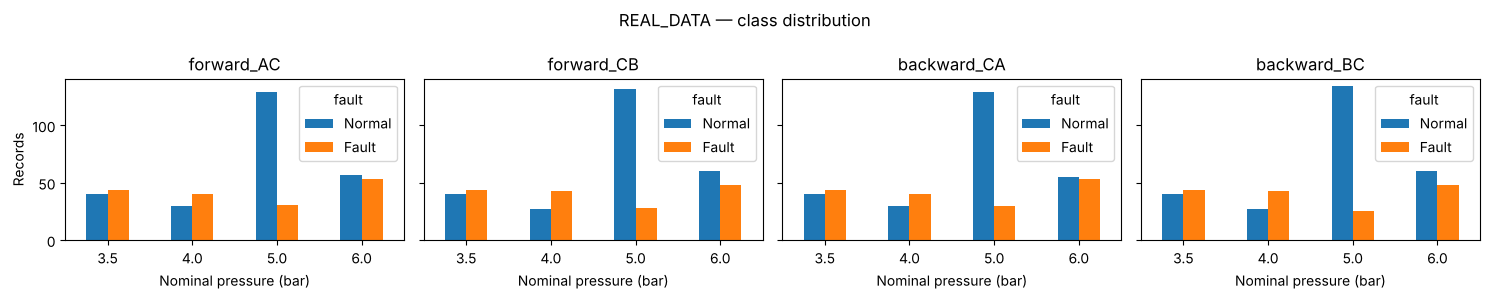

In [3]:
required = ['sample_id','segment','time_ms','pressure_bar','fault']
missing = set(required) - set(data)
if missing: raise ValueError(f'Missing columns: {sorted(missing)}')
if data[required].isna().any().any():
    raise ValueError('Missing required values: investigate raw acquisition, not silent filling.')
if data.sample_id.duplicated().any(): raise ValueError('Duplicate sample_id: inspect raw files.')
if not set(data.segment).issubset(SEGMENTS): raise ValueError('Unrecognized motion segment.')
for col in ['time_ms','pressure_bar','fault']:
    data[col] = pd.to_numeric(data[col], errors='raise')
if not np.isfinite(data[['time_ms','pressure_bar','fault']].to_numpy()).all():
    raise ValueError('Non-finite numeric input.')
if not set(data.fault).issubset({0,1}): raise ValueError('Confirm binary fault labeling.')
data['fault'] = data.fault.astype(int)
if (data.time_ms <= 0).any() or (data.pressure_bar <= 0).any():
    raise ValueError('Check units or invalid measurements.')
counts = data.groupby(['segment','pressure_bar','fault']).size().rename('n').reset_index()
counts.to_csv(RUN_DIR/'class_pressure_counts.csv',index=False)
audit = data.groupby('segment').agg(n=('fault','size'), faults=('fault','sum'))
audit['normal'] = audit.n - audit.faults
audit['fault_fraction'] = audit.faults/audit.n
audit['repeated_measurement_rows'] = data.duplicated(
    ['segment','time_ms','pressure_bar','fault'],keep=False).groupby(data.segment).sum()
audit.to_csv(RUN_DIR/'data_audit.csv')
display(audit); display(counts)
fig, axes = plt.subplots(1,4,figsize=(15,3),sharey=True)
for ax,seg in zip(axes,SEGMENTS):
    t = counts[counts.segment.eq(seg)].pivot(index='pressure_bar',columns='fault',values='n').fillna(0)
    t.rename(columns={0:'Normal',1:'Fault'}).plot.bar(ax=ax,rot=0)
    ax.set_title(seg); ax.set_xlabel('Nominal pressure (bar)'); ax.set_ylabel('Records')
fig.suptitle(TAG+' — class distribution'); fig.tight_layout()
fig.savefig(RUN_DIR/'class_distribution.png',dpi=180); plt.show()

## 5. Reanalyze the existing data without requiring a new holdout
**Requests:** R1 split/leakage, R2 #1, R3 #6.

Use whole existing sessions (or a verified acquisition block) as groups if enough actual groups exist. Otherwise run repeated stratified random-row outer CV with inner model selection. The latter is an internal-validation sensitivity analysis; it does not establish cross-session, chronological or external generalization. A data-limited design cannot be fixed by inventing acquisition metadata.

All models use the same splits; preprocessing and tuning stay inside training folds. Full mode uses 5 outer folds × 3 repeats, with 3 inner folds. Fold standard deviations are descriptive, not confidence intervals based on independent observations. Reusing records across repetitions does not increase the experimental sample size.

`HOLDOUT_SESSION_IDS` is optional and must refer only to EXISTING sessions. Leave it empty when no truly untouched portion exists. Do not relabel an already examined test split as independent. With no holdout, the main deliverables are nested outer-CV comparisons and explicit limitations; the optional holdout/CI sections skip cleanly.

In [4]:
# Choose a verified grouping column if available. Never fabricate independent groups.
GROUP_COLUMN = next((c for c in ['session_id','block_id']
                     if c in data and data[c].notna().all() and data[c].nunique() >= 3), None)
PRIMARY_GROUPED = GROUP_COLUMN is not None
if PRIMARY_GROUPED:
    # session_id below is an internal analysis-group alias if actual block IDs are used.
    # The original input snapshot preserves the original fields and provenance.
    if GROUP_COLUMN != 'session_id': data['session_id'] = data[GROUP_COLUMN].astype(str)
    data['session_id'] = data.session_id.astype(str)
    n_groups=data.session_id.nunique()
    OUTER_FOLDS=min(OUTER_FOLDS,n_groups)
    INNER_FOLDS=min(INNER_FOLDS,n_groups-int(np.ceil(n_groups/OUTER_FOLDS)))
    if INNER_FOLDS < 2: raise ValueError('Too few groups for nested CV; document this limitation.')
    print('Verified grouping column:',GROUP_COLUMN,'| outer folds:',OUTER_FOLDS,'| inner:',INNER_FOLDS)
else:
    if 'session_id' not in data: data['session_id']='UNAVAILABLE'
    else: data['session_id']=data.session_id.fillna('UNAVAILABLE').astype(str)
    print('WARNING: grouping unavailable/insufficient. Random-row CV only; within-session dependence is unresolved.')

if HOLDOUT_SESSION_IDS and not PRIMARY_GROUPED:
    raise ValueError('A group holdout requires verified real group IDs; leave IDs empty otherwise.')
if HOLDOUT_SESSION_IDS and not set(HOLDOUT_SESSION_IDS).issubset(set(data.session_id)):
    raise ValueError('Requested existing holdout IDs do not exist.')
dev=data[~data.session_id.isin(HOLDOUT_SESSION_IDS)].copy()
held=data[data.session_id.isin(HOLDOUT_SESSION_IDS)].copy()
if dev.empty: raise ValueError('No development data.')
if not held.empty:
    assert set(dev.session_id).isdisjoint(held.session_id)
    if 'cycle_id' in data and data.cycle_id.notna().all():
        if not set(dev.cycle_id).isdisjoint(held.cycle_id):
            raise ValueError('Physical cycles cross the proposed holdout boundary.')
if PRIMARY_GROUPED:
    data.groupby(['segment','session_id','pressure_bar','fault']).size().rename('n').to_csv(
        RUN_DIR/'available_group_pressure_class_counts.csv')
data[['sample_id','segment','session_id']].assign(
    partition=np.where(data.session_id.isin(HOLDOUT_SESSION_IDS),'existing_holdout','development')
).to_csv(RUN_DIR/'locked_partition.csv',index=False)

def outer_splits(frame, grouped=True):
    strata = frame.pressure_bar.astype(str)+'_'+frame.fault.astype(str)
    result = []
    for repeat in range(REPEATS):
        splitter = (StratifiedGroupKFold(n_splits=OUTER_FOLDS,shuffle=True,random_state=SEED+repeat)
                    if grouped else StratifiedKFold(n_splits=OUTER_FOLDS,shuffle=True,random_state=SEED+repeat))
        # Permute the encoding of the existing groups for each repeat. Equal class
        # profiles can otherwise produce identical group folds across random seeds.
        # This changes group ordering only; it never invents independent sessions.
        groups = frame.session_id.unique()
        aliases = dict(zip(groups,np.random.default_rng(SEED+repeat).permutation(len(groups))))
        encoded_groups = frame.session_id.map(aliases)
        iterator = splitter.split(frame,strata,encoded_groups) if grouped else splitter.split(frame,strata)
        for fold,(tr,te) in enumerate(iterator):
            if frame.iloc[tr].fault.nunique()!=2 or frame.iloc[te].fault.nunique()!=2:
                raise ValueError('A fold lacks a fault class. Reduce folds or restrict claims; do not invent samples.')
            if grouped:
                assert set(frame.iloc[tr].session_id).isdisjoint(frame.iloc[te].session_id)
                if frame.iloc[tr].session_id.nunique()<INNER_FOLDS:
                    raise ValueError('Too few independent inner-training groups.')
            result.append((repeat,fold,tr,te))
    return result

frames = {s:dev[dev.segment.eq(s)].reset_index(drop=True) for s in SEGMENTS}
splits = {s:outer_splits(f,PRIMARY_GROUPED) for s,f in frames.items()}
split_rows=[]
for seg,f in frames.items():
    for rep,fold,tr,te in splits[seg]:
        split_rows += [dict(segment=seg,repeat=rep,fold=fold,sample_id=x,role=role)
                      for ids,role in [(tr,'train'),(te,'validation')]
                      for x in f.iloc[ids].sample_id]
pd.DataFrame(split_rows).to_csv(RUN_DIR/'outer_split_manifest.csv',index=False)
print('Development rows:',len(dev),'| Optional existing-holdout rows:',len(held))

Verified grouping column: block_id | outer folds: 3 | inner: 3
Development rows: 1688 | Optional existing-holdout rows: 0


## 6. Baselines and evaluation functions
**Request:** R3 #8 and #10. **Action:** include a no-skill baseline, a linear model, a single
tree, SVM/SVR, MLP, RF and gradient boosting. Use identical splits and a small predeclared
search space. Full mode expands tuning, but is not an exhaustive benchmark.
Fault classification is selected by **macro F1**, pressure estimation by **RMSE in bar**.
Targets are never standardized, so regression units stay physical. Threshold is the default
classifier decision rule; any threshold optimization must take place in inner training only.
Convergence warnings are counted and exported: resolve them before drawing comparisons.

In [5]:
TREES = 40 if FAST_DEMO else 200
ITER = 150 if FAST_DEMO else 1500
def candidates(task):
    if task=='fault':
        models = {
          'Dummy':(DummyClassifier(strategy='prior'),{}),
          'Linear':(LogisticRegression(max_iter=1500,random_state=SEED),{'m__C':[0.1,1.0]}),
          'Tree':(DecisionTreeClassifier(random_state=SEED),{'m__max_depth':[2,4]}),
          'SVM':(SVC(probability=False,random_state=SEED),{'m__C':[0.1,1.0]}),
          'MLP':(MLPClassifier(hidden_layer_sizes=(16,),max_iter=ITER,early_stopping=False,
                              random_state=SEED),{'m__alpha':[0.001]}),
          'RF':(RandomForestClassifier(n_estimators=TREES,random_state=SEED,n_jobs=1),
                {'m__min_samples_leaf':[1,4]}),
          'GB':(GradientBoostingClassifier(n_estimators=40 if FAST_DEMO else 150,
                                         random_state=SEED),{'m__max_depth':[1,2]})}
    else:
        models = {
          'Dummy':(DummyRegressor(strategy='mean'),{}),
          'Linear':(Ridge(),{'m__alpha':[0.1,10.0]}),
          'Tree':(DecisionTreeRegressor(random_state=SEED),{'m__max_depth':[2,4]}),
          'SVR':(SVR(),{'m__C':[1.0,10.0]}),
          'MLP':(MLPRegressor(hidden_layer_sizes=(16,),max_iter=ITER,early_stopping=False,
                             random_state=SEED),{'m__alpha':[0.001]}),
          'RF':(RandomForestRegressor(n_estimators=TREES,random_state=SEED,n_jobs=1),
                {'m__min_samples_leaf':[1,4]}),
          'GB':(GradientBoostingRegressor(n_estimators=40 if FAST_DEMO else 150,
                                         random_state=SEED),{'m__max_depth':[1,2]})}
    if not FAST_DEMO:
        models['MLP'][1]['m__alpha']=[0.001,0.01]
    return {k:(Pipeline([('scale',StandardScaler()),('m',m)]),g) for k,(m,g) in models.items()}

def metrics(y,p,task,score=None):
    if task=='pressure':
        return dict(mae_bar=mean_absolute_error(y,p),rmse_bar=np.sqrt(mean_squared_error(y,p)),
                    r2=r2_score(y,p) if np.var(y)>0 else np.nan)
    tn,fp,fn,tp = confusion_matrix(y,p,labels=[0,1]).ravel()
    out=dict(accuracy=accuracy_score(y,p),balanced_accuracy=balanced_accuracy_score(y,p),
             macro_f1=f1_score(y,p,average='macro',zero_division=0),
             fault_precision=precision_score(y,p,zero_division=0),
             fault_recall=recall_score(y,p,zero_division=0),
             false_alarm_rate=fp/(fp+tn) if fp+tn else np.nan,
             tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp))
    if score is not None and len(np.unique(y))==2:
        out.update(roc_auc=roc_auc_score(y,score),average_precision=average_precision_score(y,score))
    return out

def scores_of(model,X):
    if hasattr(model,'predict_proba'): return model.predict_proba(X)[:,1]
    if hasattr(model,'decision_function'): return model.decision_function(X)
    return None

warning_log=[]
def fit_search(frame,features,task,model_name,grouped=None):
    grouped = PRIMARY_GROUPED if grouped is None else grouped
    model,grid=candidates(task)[model_name]
    y=frame.fault if task=='fault' else frame.pressure_bar
    cv=GroupKFold(INNER_FOLDS) if grouped else StratifiedKFold(INNER_FOLDS,shuffle=True,random_state=SEED)
    # Random-row diagnostic only uses the fault task; grouped regression uses GroupKFold.
    cv_splits=list(cv.split(frame,y,frame.session_id) if grouped else cv.split(frame,y.astype(str)))
    if task=='fault' and any(frame.iloc[a].fault.nunique()<2 for a,b in cv_splits):
        raise ValueError('Inner training fold lacks a class; reduce folds or document an unsupported comparison.')
    search=GridSearchCV(model,grid,cv=cv_splits,
        scoring='f1_macro' if task=='fault' else 'neg_root_mean_squared_error',
        n_jobs=1,error_score='raise',refit=True)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always',ConvergenceWarning)
        search.fit(frame[features],y)
    warning_log.extend(dict(model=model_name,task=task,message=str(w.message)) for w in caught)
    return search.best_estimator_,search.best_params_

## 7. Repeated nested CV on existing records: fault and pressure baselines
**Requests:** R2 #1; R3 #6, #8, #10. **Output:** fold-level metrics, hyperparameters,
out-of-fold predictions, means and fold SDs. Values are fractions (multiply by 100 for %).
The tuning score from inner CV is not a final test score. Report convergence problems,
and do not call a one- or two-record improvement statistically significant.

If acquisition grouping is unavailable, output labels and the run manifest explicitly identify random-row CV. Do not report that run as session-independent validation.

In [6]:
fold_results=[]; prediction_rows=[]
for seg,frame in frames.items():
    print('Running',seg,flush=True)
    for task in ['fault','pressure']:
        features=['time_ms','pressure_bar'] if task=='fault' else ['time_ms']
        target='fault' if task=='fault' else 'pressure_bar'
        for name in candidates(task):
            for rep,fold,tr,te in splits[seg]:
                train,test=frame.iloc[tr],frame.iloc[te]
                model,params=fit_search(train,features,task,name)
                pred=model.predict(test[features]); score=scores_of(model,test[features]) if task=='fault' else None
                fold_results.append(dict(segment=seg,task=task,model=name,repeat=rep,fold=fold,
                    params=json.dumps(params),**metrics(test[target],pred,task,score)))
                for pos,(_,row) in enumerate(test.iterrows()):
                    prediction_rows.append(dict(segment=seg,task=task,model=name,repeat=rep,fold=fold,
                        sample_id=row.sample_id,session_id=row.session_id,y_true=row[target],y_pred=pred[pos]))
results=pd.DataFrame(fold_results); oof=pd.DataFrame(prediction_rows)
results.to_csv(RUN_DIR/'nested_cv_fold_metrics.csv',index=False)
oof.to_csv(RUN_DIR/'nested_cv_predictions.csv',index=False)
summary=results.groupby(['segment','task','model']).agg(
    {k:['mean','std'] for k in ['accuracy','macro_f1','fault_recall','false_alarm_rate','rmse_bar','mae_bar','r2']})
summary.to_csv(RUN_DIR/'nested_cv_mean_sd.csv')
display(summary.round(3))
print('Convergence warnings so far:',len(warning_log),'— inspect warning_log.csv before interpreting MLP.')

Running forward_AC
Running forward_CB
Running backward_CA
Running backward_BC


accuracy        macro_f1        fault_recall        false_alarm_rate        rmse_bar        mae_bar            r2       
                                mean    std     mean    std         mean    std             mean    std     mean    std    mean    std   mean    std
segment     task     model                                                                                                                          
backward_BC fault    Dummy     0.361  0.194    0.251  0.115        0.333  0.500            0.333  0.500      NaN    NaN     NaN    NaN    NaN    NaN
                     GB        0.842  0.094    0.821  0.071        0.737  0.151            0.054  0.042      NaN    NaN     NaN    NaN    NaN    NaN
                     Linear    0.413  0.222    0.349  0.178        0.427  0.430            0.328  0.492      NaN    NaN     NaN    NaN    NaN    NaN
                     MLP       0.740  0.087    0.713  0.119        0.776  0.171            0.182  0.175      NaN    NaN     NaN    NaN    NaN    NaN
                     RF        0.892  0.066    0.874  0.052        0.877  0.127            0.068  0.014      NaN    NaN     NaN    NaN    NaN    NaN
                     SVM       0.864  0.096    0.849  0.084        0.764  0.191            0.016  0.014      NaN    NaN     NaN    NaN    NaN    NaN
                     Tree      0.765  0.172    0.735  0.189        0.555  0.303            0.041  0.051      NaN    NaN     NaN    NaN    NaN    NaN
            pressure Dummy       NaN    NaN      NaN    NaN          NaN    NaN              NaN    NaN    0.867  0.349   0.798  0.353 -0.043  0.032
                     GB          NaN    NaN      NaN    NaN          NaN    NaN              NaN    NaN    0.301  0.145   0.186  0.092  0.882  0.038
                     Linear      NaN    NaN      NaN    NaN          NaN    NaN              NaN    NaN    0.486  0.055   0.429  0.029  0.486  0.411
                     MLP         NaN    NaN      NaN    NaN          NaN    NaN              NaN    NaN    0.492  0.047   0.429  0.052  0.407  0.548
                     RF          NaN    NaN      NaN    NaN          NaN    NaN              NaN    NaN    0.311  0.127   0.183  0.069  0.866  0.016
                     SVR         NaN    NaN      NaN    NaN          NaN    NaN              NaN    NaN    0.419  0.077   0.318  0.047  0.643  0.253
                     Tree        NaN    NaN      NaN    NaN          NaN    NaN              NaN    NaN    0.310  0.163   0.190  0.088  0.878  0.053
backward_CA fault    Dummy     0.330  0.186    0.234  0.115        0.333  0.500            0.333  0.500      NaN    NaN     NaN    NaN    NaN    NaN
                     GB        0.851  0.066    0.812  0.076        0.858  0.147            0.100  0.057      NaN    NaN     NaN    NaN    NaN    NaN
                     Linear    0.466  0.250    0.438  0.247        0.538  0.394            0.297  0.446      NaN    NaN     NaN    NaN    NaN    NaN
                     MLP       0.746  0.154    0.722  0.188        0.844  0.130            0.195  0.237      NaN    NaN     NaN    NaN    NaN    NaN
                     RF        0.864  0.042    0.824  0.075        0.894  0.107            0.111  0.053      NaN    NaN     NaN    NaN    NaN    NaN
                     SVM       0.898  0.102    0.897  0.102        0.843  0.163            0.022  0.065      NaN    NaN     NaN    NaN    NaN    NaN
                     Tree      0.778  0.172    0.770  0.178        0.797  0.282            0.200  0.265      NaN    NaN     NaN    NaN    NaN    NaN
            pressure Dummy       NaN    NaN      NaN    NaN          NaN    NaN              NaN    NaN    0.867  0.349   0.798  0.353 -0.043  0.032
                     GB          NaN    NaN      NaN    NaN          NaN    NaN              NaN    NaN    0.694  0.155   0.561  0.193 -0.868  2.338
                     Linear      NaN    NaN      NaN    NaN          NaN    NaN              NaN    NaN    0.616  0.112   0.527  0.094  0.253  0.502
     

Convergence warnings so far: 303 — inspect warning_log.csv before interpreting MLP.


## 8. Feature ablation and a leakage sensitivity diagnostic
**Requests:** R1 Time-only and random splits; R3 #9.
Train RF with Time-only, Pressure-only and both. Fit/tune each on the same primary-protocol folds.
Paired fold differences quantify sensitivity but are not independent replicates.
The Pressure-only model is fitted on TRAINING labels; never compute a majority lookup
using the whole dataset and compare it with held-out accuracy.

When verified groups exist, compare fixed RF on random-row versus grouped splits as a diagnostic. Otherwise only random-row results are produced.
This difference alone does not prove leakage: the evaluation populations differ.
Neither diagnostic accesses an optional existing holdout.

In [7]:
ablation=[]; diagnostic=[]
for seg,frame in frames.items():
    for label,features in {'Time':['time_ms'],'Pressure':['pressure_bar'],
                           'Both':['time_ms','pressure_bar']}.items():
        for rep,fold,tr,te in splits[seg]:
            model,_=fit_search(frame.iloc[tr],features,'fault','RF')
            test=frame.iloc[te];pred=model.predict(test[features])
            ablation.append(dict(segment=seg,features=label,repeat=rep,fold=fold,
                                  **metrics(test.fault,pred,'fault')))
    for protocol in (['grouped','random_rows'] if PRIMARY_GROUPED else ['random_rows']):
        protocol_splits=splits[seg] if protocol=='grouped' else outer_splits(frame,False)
        for rep,fold,tr,te in protocol_splits:
            m=RandomForestClassifier(n_estimators=TREES,min_samples_leaf=4,random_state=SEED,n_jobs=1)
            m.fit(frame.iloc[tr][['time_ms','pressure_bar']],frame.iloc[tr].fault)
            p=m.predict(frame.iloc[te][['time_ms','pressure_bar']])
            diagnostic.append(dict(segment=seg,protocol=protocol,repeat=rep,fold=fold,
                                   **metrics(frame.iloc[te].fault,p,'fault')))
abl=pd.DataFrame(ablation);diag=pd.DataFrame(diagnostic)
abl.to_csv(RUN_DIR/'ablation_fold_metrics.csv',index=False)
paired=abl.pivot(index=['segment','repeat','fold'],columns='features',values='macro_f1')
paired['both_minus_time']=paired.Both-paired.Time
paired.to_csv(RUN_DIR/'ablation_paired_differences.csv')
diag.to_csv(RUN_DIR/'random_vs_grouped_diagnostic.csv',index=False)
display(abl.groupby(['segment','features'])[['macro_f1','fault_recall','false_alarm_rate']].mean())
display(paired.groupby('segment').both_minus_time.agg(['mean','std']))

macro_f1  fault_recall  false_alarm_rate
segment     features                                          
backward_BC Both      0.873522      0.876984          0.067905
            Pressure  0.376597      0.583333          0.537037
            Time      0.794230      0.778373          0.135629
backward_CA Both      0.824065      0.894459          0.111449
            Pressure  0.307108      0.653990          0.708999
            Time      0.842968      0.852991          0.078731
forward_AC  Both      0.873358      0.890253          0.053143
            Pressure  0.305332      0.644044          0.705034
            Time      0.878223      0.861303          0.038620
forward_CB  Both      0.618003      0.845949          0.399907
            Pressure  0.452599      0.534793          0.441002
            Time      0.567736      0.782610          0.462863

,mean,std
segment,,
backward_BC,0.079293,0.030309
backward_CA,-0.018903,0.081658
forward_AC,-0.004865,0.043012
forward_CB,0.050267,0.052535


## 9. Pressure-level estimation, classification alternative and unseen-level stress test
**Requests:** R1 regression rationale; R2 #3; R3 #7.
Use Time alone to estimate pressure; including Pressure as an input would leak the target.
Train an RF classifier on the observed pressure categories, then decode its predicted class
to bar and score with the same MAE/RMSE/R² definitions as the regressor. Label accuracy is
reported separately; do not compare accuracy numerically with R².

The leave-one-pressure-level-out experiment below uses development data only. Interior
levels are an interpolation stress test, endpoints are extrapolation. This withholds a setting,
but is **not independent-session evidence**, since other settings from those sessions remain
in training. Trees do not extrapolate beyond their training target range. No new-pressure or new-session measurements are available for this revision; state that interpolation and external robustness remain unvalidated. No unseen-pressure result from synthetic data
supports a manuscript claim.

In [8]:
pressure_classes=[];unseen=[]
for seg,frame in frames.items():
    for rep,fold,tr,te in splits[seg]:
        train,test=frame.iloc[tr],frame.iloc[te]
        levels=np.sort(train.pressure_bar.unique())
        if not set(test.pressure_bar).issubset(levels):
            raise ValueError('Pressure-category comparison requires all validation levels in training.')
        y=np.searchsorted(levels,train.pressure_bar)
        clf=RandomForestClassifier(n_estimators=TREES,min_samples_leaf=4,random_state=SEED,n_jobs=1)
        clf.fit(train[['time_ms']],y)
        pred=levels[clf.predict(test[['time_ms']])]
        pressure_classes.append(dict(segment=seg,repeat=rep,fold=fold,
            level_accuracy=accuracy_score(test.pressure_bar.astype(str),pred.astype(str)),
            **metrics(test.pressure_bar,pred,'pressure')))
    levels=np.sort(frame.pressure_bar.unique())
    for level in levels:
        train=frame[frame.pressure_bar.ne(level)];test=frame[frame.pressure_bar.eq(level)]
        m=RandomForestRegressor(n_estimators=TREES,min_samples_leaf=4,random_state=SEED,n_jobs=1)
        m.fit(train[['time_ms']],train.pressure_bar);pred=m.predict(test[['time_ms']])
        unseen.append(dict(segment=seg,withheld_bar=level,n_test=len(test),
            test_type='extrapolation' if level in [levels.min(),levels.max()] else 'interior level',
            mae_bar=mean_absolute_error(test.pressure_bar,pred),
            rmse_bar=np.sqrt(mean_squared_error(test.pressure_bar,pred))))
pc=pd.DataFrame(pressure_classes); unseen=pd.DataFrame(unseen)
pc.to_csv(RUN_DIR/'pressure_classifier_fold_metrics.csv',index=False)
unseen.to_csv(RUN_DIR/'leave_pressure_level_out.csv',index=False)
display(pc.groupby('segment')[['level_accuracy','rmse_bar','mae_bar']].mean())
display(unseen)

,level_accuracy,rmse_bar,mae_bar
segment,,,
backward_BC,0.783335,0.376383,0.166836
backward_CA,0.468792,0.768749,0.536933
forward_AC,0.537497,0.717926,0.465605
forward_CB,0.605009,0.596965,0.361637


,segment,withheld_bar,n_test,test_type,mae_bar,rmse_bar
0,forward_AC,3.5,84,extrapolation,0.907068,0.929973
1,forward_AC,4.0,70,interior level,0.293878,0.390679
2,forward_AC,5.0,160,interior level,1.190677,1.192815
3,forward_AC,6.0,110,extrapolation,1.000000,1.000000
4,forward_CB,3.5,84,extrapolation,0.934923,0.951492
5,forward_CB,4.0,70,interior level,0.599570,0.700354
6,forward_CB,5.0,160,interior level,1.050111,1.058286
7,forward_CB,6.0,108,extrapolation,1.000000,1.000000
8,backward_CA,3.5,84,extrapolation,0.990314,1.013184
9,backward_CA,4.0,70,interior level,0.471073,0.560736


## 10. Optional existing holdout — skip when none remains untouched
Select models using development CV only, then refit and evaluate an existing, predeclared holdout once if one is genuinely available. Do not create the appearance of new independent evidence by repartitioning already examined data. With `HOLDOUT_SESSION_IDS=[]`, this section produces no holdout metrics. Use the outer-CV results and report their limitations. Selecting the best model from outer-CV means makes its winning mean optimistic; preserve all model results and avoid claiming an unbiased estimate of that selected winner without an untouched test set.

In [9]:
holdout_rows=[];holdout_metrics=[];fitted={};selected=[]
for seg,frame in frames.items():
    test=held[held.segment.eq(seg)].copy()
    if test.empty: continue
    if test.empty or test.fault.nunique()<2: raise ValueError('Holdout needs both fault classes per segment.')
    for task in ['fault','pressure']:
        metric='macro_f1' if task=='fault' else 'rmse_bar'
        means=results[(results.segment.eq(seg))&(results.task.eq(task))].groupby('model')[metric].mean()
        name=means.idxmax() if task=='fault' else means.idxmin()
        features=['time_ms','pressure_bar'] if task=='fault' else ['time_ms']
        m,params=fit_search(frame,features,task,name);fitted[(seg,task)]=(m,features)
        target='fault' if task=='fault' else 'pressure_bar'
        pred=m.predict(test[features]);scores=scores_of(m,test[features]) if task=='fault' else None
        selected.append(dict(segment=seg,task=task,model=name,params=json.dumps(params)))
        holdout_metrics.append(dict(segment=seg,task=task,model=name,
                                   **metrics(test[target],pred,task,scores)))
        for i,(_,r) in enumerate(test.iterrows()):
            holdout_rows.append(dict(segment=seg,task=task,model=name,sample_id=r.sample_id,
                session_id=r.session_id,y_true=r[target],y_pred=pred[i]))
hp=pd.DataFrame(holdout_rows,columns=['segment','task','model','sample_id','session_id','y_true','y_pred']);hm=pd.DataFrame(holdout_metrics)
pd.DataFrame(selected).to_csv(RUN_DIR/'frozen_model_selection.csv',index=False)
hp.to_csv(RUN_DIR/'holdout_predictions.csv',index=False)
hm.to_csv(RUN_DIR/'holdout_metrics.csv',index=False)
display(hm.round(3))
if hp.empty:
    print('No untouched existing holdout: no holdout performance is claimed.')
else:
    fig,axes=plt.subplots(1,4,figsize=(13,3))
    for ax,seg in zip(axes,SEGMENTS):
        p=hp[hp.segment.eq(seg)&hp.task.eq('fault')]
        cm=confusion_matrix(p.y_true,p.y_pred,labels=[0,1]);ax.imshow(cm,cmap='Blues')
        for i in range(2):
            for j in range(2):ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=13)
        ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Normal','Fault'],yticklabels=['Normal','Fault'],
               xlabel='Predicted',ylabel='True',title=seg)
    fig.suptitle(TAG+' — optional existing-group holdout');fig.tight_layout()
    fig.savefig(RUN_DIR/'holdout_confusion_matrices.png',dpi=200);plt.show()

""


No untouched existing holdout: no holdout performance is claimed.


## 11. Optional uncertainty on an existing untouched group holdout
This section skips if no genuine holdout exists. If one does exist, resample whole available groups; these conditional intervals do not include model-selection/retraining uncertainty. Few groups yield unreliable intervals. Without independent metadata, we do not fabricate session-based intervals. Report repeated-fold SDs as variability, clearly state their dependence, and explicitly acknowledge the absence of independent-session uncertainty estimates. No new data collection is required by this workflow.

In [10]:
interval_rows=[]
if hp.empty: print('Skipped holdout confidence intervals: no untouched existing holdout.')
for (seg,task),p in hp.groupby(['segment','task']):
    groups=p.session_id.unique();rng=np.random.default_rng(SEED)
    keys=['macro_f1','fault_recall','false_alarm_rate'] if task=='fault' else ['rmse_bar','mae_bar','r2']
    draws={k:[] for k in keys}
    for b in range(BOOTSTRAPS):
        ids=rng.choice(groups,len(groups),replace=True)
        sample=pd.concat([p[p.session_id.eq(g)] for g in ids],ignore_index=True)
        if task=='fault' and sample.y_true.nunique()<2:continue
        vals=metrics(sample.y_true,sample.y_pred,task)
        for k in keys:draws[k].append(vals[k])
    for k in keys:
        a=np.asarray(draws[k]);a=a[np.isfinite(a)]
        lo,hi=np.quantile(a,[.025,.975]) if len(a) else [np.nan,np.nan]
        interval_rows.append(dict(segment=seg,task=task,metric=k,low=lo,high=hi,
            independent_sessions=len(groups),valid_resamples=len(a),
            caution='TOO FEW SESSIONS FOR RELIABLE INTERVALS' if len(groups)<5 else 'Conditional on fitted model'))
ci=pd.DataFrame(interval_rows);ci.to_csv(RUN_DIR/'holdout_cluster_bootstrap_intervals.csv',index=False)
display(ci.round(3))

Skipped holdout confidence intervals: no untouched existing holdout.


""


## 12. Controlled augmentation pilot — training only
**Request:** R2 #5 (small-data augmentation). Add noise to **transit time only** after splitting,
on outer training records only. Do not synthesize fault labels or jitter discrete pressure targets.
Below is a predeclared RF pilot with no tuning; its unaugmented control uses the same model
and splits. Extra copies are correlated training points, not new independent samples.

The demo jitter is arbitrary. For real data, use an existing documented timing-repeatability estimate, if available; set the noise scale before viewing validation outcomes. Record why
noise preserves the fault label. Leave this section disabled if there is no justified noise model.
Any augmentation selected for final deployment must be placed inside a training-only estimator
and tuned in inner CV, evaluated within the same nested validation protocol; this pilot alone is exploratory. No new physical measurements are requested. If calibration evidence is absent, skip augmentation and discuss it as future work.

In [11]:
JITTER_SD_MS = 30.0 if USE_SYNTHETIC else None
augmentation=[]
if JITTER_SD_MS is None:
    print('Skipped: supply independently calibrated timing noise before real augmentation.')
else:
    for seg,frame in frames.items():
        for rep,fold,tr,te in splits[seg]:
            original=frame.iloc[tr].copy();test=frame.iloc[te]
            rng=np.random.default_rng(SEED+100*rep+fold)
            noisy=original.copy()
            noisy['time_ms']=np.maximum(1,noisy.time_ms+rng.normal(0,JITTER_SD_MS,len(noisy)))
            for label,train in [('none',original),('timing_jitter',pd.concat([original,noisy]))]:
                m=RandomForestClassifier(n_estimators=TREES,min_samples_leaf=4,random_state=SEED,n_jobs=1)
                m.fit(train[['time_ms','pressure_bar']],train.fault)
                pred=m.predict(test[['time_ms','pressure_bar']])
                augmentation.append(dict(segment=seg,repeat=rep,fold=fold,augmentation=label,
                                          **metrics(test.fault,pred,'fault')))
    aug=pd.DataFrame(augmentation);aug.to_csv(RUN_DIR/'augmentation_pilot.csv',index=False)
    display(aug.groupby(['segment','augmentation'])[['macro_f1','fault_recall']].mean())

Skipped: supply independently calibrated timing noise before real augmentation.


## 13. Recover available evidence; document experiments that cannot be performed
**Requests:** R1 experimental protocol; R2 cycles/latency; R3 #3–7 and #11.

No new physical experiments or data acquisition are planned for this revision.

1. Ask the authors for the original CSVs, saved train/test indices, excluded rows and existing acquisition logs. Resolve the 424/421 counts from actual records.
2. Recover session/block/cycle identities, acquisition order, durations, cycles per pressure/fault condition, load and fault-label definitions only where documented. If irrecoverable, say so and use the qualified random-row analysis; do not invent metadata.
3. Specify that only four nominal pressure settings and the actually documented fault/severity conditions were studied. Compare pressure categories and regressors computationally, but do not claim continuous-pressure interpolation or broader fault robustness.
4. Use existing genuine message logs only if all expected messages, endpoints and clock synchronization are already recorded. Otherwise do not estimate live latency from offline inference timings, screenshots or simulated dashboard signals. Remove or qualify unsupported real-time, production-ready, reliability and cost claims.
5. Keep the distinction between fault classification/condition monitoring and prediction of future failures. No run-to-failure data means no validated remaining-useful-life prediction.

The optional helper below is retained solely for already recorded telemetry. It is not a request to run hardware or generate new logs. Missing live evidence is answered respectfully as an unperformed experiment and a study limitation. Never describe synthetic latency as measured performance.

In [12]:
def analyze_live_telemetry(path, clocks_synchronized=False):
    if not clocks_synchronized:
        raise ValueError('Document clock synchronization before computing cross-host latency.')
    t=pd.read_csv(path)
    cols=['message_id','session_id','source','delivered','plc_time_ms',
          'inference_start_ms','inference_end_ms','dashboard_time_ms']
    if set(cols)-set(t):raise ValueError('Missing telemetry columns: '+str(set(cols)-set(t)))
    if not t.source.eq('live').all():raise ValueError('Keep simulated and live telemetry separate.')
    if t.message_id.duplicated().any():raise ValueError('Log duplicate deliveries separately; resolve message IDs.')
    if not t.delivered.isin([0,1]).all():raise ValueError('delivered must be 0 or 1.')
    numeric=['plc_time_ms','inference_start_ms','inference_end_ms','dashboard_time_ms']
    for c in numeric:t[c]=pd.to_numeric(t[c],errors='raise')
    if t[['message_id','session_id','plc_time_ms']].isna().any().any():raise ValueError('Missing sent-message data.')
    d=t[t.delivered.eq(1)].copy()
    if d.empty or d[numeric].isna().any().any():raise ValueError('Missing delivered-message timestamps.')
    order=d[numeric].to_numpy()
    if not np.isfinite(order).all() or (np.diff(order,axis=1)<0).any():
        raise ValueError('Invalid event ordering or unsynchronized clocks.')
    d['end_to_end_ms']=d.dashboard_time_ms-d.plc_time_ms
    d['inference_ms']=d.inference_end_ms-d.inference_start_ms
    rows=[]
    for session,s in t.groupby('session_id'):
        delivered=d[d.session_id.eq(session)].sort_values('dashboard_time_ms')
        elapsed=(s.plc_time_ms.max()-s.plc_time_ms.min())/1000
        intervals=np.diff(delivered.dashboard_time_ms)/1000
        rows.append(dict(session_id=session,n_expected=len(s),n_delivered=len(delivered),
            delivery_fraction=s.delivered.mean(),observed_send_span_s=elapsed,
            median_latency_ms=delivered.end_to_end_ms.median(),
            p95_latency_ms=delivered.end_to_end_ms.quantile(.95),
            p99_latency_ms=delivered.end_to_end_ms.quantile(.99),
            median_inference_ms=delivered.inference_ms.median(),
            median_update_interval_s=np.median(intervals) if len(intervals) else np.nan))
    return pd.DataFrame(rows)

TELEMETRY_CSV = None  # Path to EXISTING genuine logs only, if already available.
CLOCKS_SYNCHRONIZED = False
if TELEMETRY_CSV:
    live=analyze_live_telemetry(TELEMETRY_CSV,CLOCKS_SYNCHRONIZED)
    live.to_csv(RUN_DIR/'REAL_live_telemetry_metrics.csv',index=False);display(live)
else:
    print('No real telemetry supplied. Live latency/reliability cannot be reported; state this limitation in the response.')

No real telemetry supplied. Live latency/reliability cannot be reported; state this limitation in the response.


## 14. Evidence exports and respectful response wording
The export contains audit counts, splits, models, predictions, metrics and versions. Synthetic examples must never enter the manuscript. Review the actual analyses before filling any numerical placeholder.

### What can be answered by reanalysis
- **Repeated CV/baselines:** We thank the reviewer for this suggestion. Using the existing dataset, we have [only after actually running: performed repeated nested ... cross-validation and compared ...]. Table [X] reports [actual metrics and variability]. [Where metadata are absent:] Acquisition-session identifiers were not retained, so this analysis cannot rule out within-session dependence or establish external generalization; this limitation is stated explicitly.
- **Ablation/metrics:** We have [only after completion] compared Time-only, Pressure-only and both using identical splits and training-only preprocessing, and added [verified metrics]. The results support [limited finding], without interpreting impurity importance as causal evidence.

### Requests requiring unavailable physical experiments
- **R3 #4 dataset expansion / #6 independent sessions:** We appreciate the recommendation and agree that additional independent acquisitions would strengthen the study. Additional data collection is not feasible within the current revision, so we have not expanded the experimental dataset or claimed new-session validation. We instead [completed existing-data analyses], clarified the actual sample distributions and exclusions, and explicitly limited the conclusions to this laboratory dataset.
- **R3 #7 intermediate pressures:** We agree that newly measured intermediate settings would be needed to establish interpolation capability. These experiments could not be performed for this revision. We therefore describe the task as pressure-level estimation at the four observed settings, add [completed computational comparison if available], and remove claims of validated continuous-pressure interpolation.
- **R2 latency / R3 #11 live testing:** We acknowledge the value of a live PLC-to-dashboard assessment. No new live experiment was possible and the existing records do not provide [confirm actual missing instrumentation]. Accordingly, we do not report measured end-to-end latency or delivery reliability, clarify that the dashboard demonstration uses simulated telemetry, and qualify the real-time/deployment claims.
- **Augmentation:** We discuss augmentation for small industrial datasets, but do not treat synthetic samples as independent acquisitions. If existing calibration cannot justify label-preserving perturbations, no augmentation-performance claim is made.

Do not say a suggested test was conducted when it was not. Do not invent reasons such as hardware failure, access restrictions or a deadline unless the authors confirm them. Reviewer acceptance cannot be guaranteed; stronger limitations are an honest response, not a substitute claim of equivalent validation.

### Manuscript alignment checklist
Audit every existing 'we added/performed' response against actual changed text, tables and executed results. Reduce generalized predictive-maintenance claims to the demonstrated fault/pressure monitoring scope where appropriate. Check Figure 11's changed panel order, code formatting, reference metadata, data/code availability and journal declarations. Editorial/literature changes are separate from these computations.

Methodological references: [grouped CV](https://scikit-learn.org/stable/modules/cross_validation.html), [nested CV](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html), [leakage prevention](https://scikit-learn.org/stable/common_pitfalls.html).

In [13]:
pd.DataFrame(warning_log,columns=['model','task','message']).to_csv(RUN_DIR/'warning_log.csv',index=False)
manifest=dict(data_status=TAG,synthetic=USE_SYNTHETIC,fast_demo=FAST_DEMO,seed=SEED,
    revision_scope='Existing data only; no new physical experiments',
    validation_protocol='grouped' if PRIMARY_GROUPED else 'random_rows_with_dependence_limitation',
    verified_group_column=GROUP_COLUMN,
    outer_folds=OUTER_FOLDS,repeats=REPEATS,inner_folds=INNER_FOLDS,
    bootstrap_resamples=BOOTSTRAPS,holdout_sessions=HOLDOUT_SESSION_IDS,
    fault_selection='macro F1',pressure_selection='RMSE in bar',
    versions={p:__import__(p).__version__ for p in ['numpy','pandas','sklearn','matplotlib']},
    python=platform.python_version(),input_hashes=input_hashes,
    generated_snapshot_sha256=hashlib.sha256((RUN_DIR/'input_snapshot.csv').read_bytes()).hexdigest(),
    warning_count=len(warning_log),real_live_experiment_completed=bool(TELEMETRY_CSV))
(RUN_DIR/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
(RUN_DIR/'READ_ME_FIRST.txt').write_text(
    'SYNTHETIC DEMONSTRATION ONLY. NOT MANUSCRIPT EVIDENCE. Replace with real data and rerun.'
    if USE_SYNTHETIC else
    'REAL-DATA COMPUTATION. Verify provenance, grouping, units, convergence and limitations before publication.')
archive=Path(f'{TAG}_revision_results.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for f in sorted(RUN_DIR.rglob('*')):
        if f.is_file():z.write(f,str(f.relative_to(RUN_DIR)))
print('Export ready:',archive.resolve())
print('Replace synthetic inputs with collected data; no new acquisition is requested.' if USE_SYNTHETIC else 'Review evidence and stated limitations before manuscript use.')
# Optional Colab download (uncomment):
# from google.colab import files
# files.download(str(archive))

Export ready: REAL_DATA_revision_results.zip
Review evidence and stated limitations before manuscript use.
